# 01 Data Understanding and EDA

This notebook checks data quality, describes the students, compares dropout rates across groups, and uses two simple statistical tests. The aim is to understand the problem before modelling.

### What and why
Load the shared helper so every notebook cleans column names and creates the same binary target.

In [1]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, ttest_ind
from data_utils import load_data
from plot_utils import set_style, save_figure

set_style()
data = load_data()
data.head()


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,dropout
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
1,1,15,1,9254,1,1,160.0,1,1,3,...,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,0
2,1,1,5,9070,1,1,122.0,1,37,37,...,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout,1
3,1,17,2,9773,1,1,122.0,1,38,37,...,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,0
4,2,39,1,8014,0,1,100.0,1,37,38,...,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,0


### What and why
Inspect shape, data types, missing values, and duplicate rows. These checks reveal data-quality issues before analysis.

In [2]:
print("Shape:", data.shape)
display(data.dtypes.to_frame("dtype").head(10))
print("Missing values:", int(data.isna().sum().sum()))
print("Duplicate rows:", int(data.duplicated().sum()))
print("Target counts:")
display(data["Target"].value_counts())


Shape: (4424, 38)


,dtype
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Previous qualification (grade),float64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64


Missing values: 0
Duplicate rows: 0
Target counts:


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

### What and why
Calculate descriptive statistics for important academic, demographic, and financial variables. Mean, median, spread, range, and skewness show typical values and unusual asymmetry.

In [3]:
key_numeric = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)",
]
summary = data[key_numeric].agg(["mean", "median", "std", "min", "max"]).T
summary["skewness"] = data[key_numeric].skew()
display(summary.round(2))


,mean,median,std,min,max,skewness
Age at enrollment,23.27,20.00,7.59,17.0,70.00,2.05
Admission grade,126.98,126.10,14.48,95.0,190.00,0.53
Curricular units 1st sem (approved),4.71,5.00,3.09,0.0,26.00,0.77
Curricular units 2nd sem (approved),4.44,5.00,3.01,0.0,20.00,0.31
Curricular units 1st sem (grade),10.64,12.29,4.84,0.0,18.88,-1.57
Curricular units 2nd sem (grade),10.23,12.20,5.21,0.0,18.57,-1.31


### What and why
Check the binary class balance. A visible imbalance explains why recall, PR-AUC, class weights, and SMOTE are considered later.

,class,count,percentage
0,Not dropout,3003,67.879747
1,Dropout,1421,32.120253


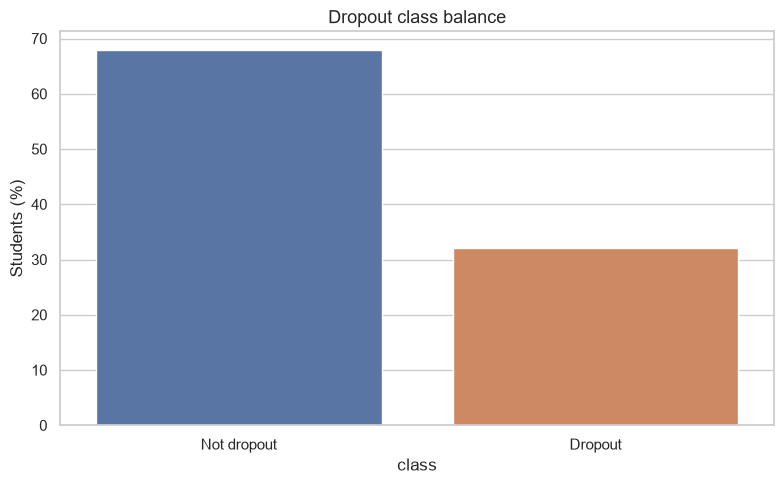

In [4]:
balance = data["dropout"].value_counts().rename(index={0: "Not dropout", 1: "Dropout"}).rename_axis("class").reset_index(name="count")
balance["percentage"] = 100 * balance["count"] / len(data)
display(balance)
sns.barplot(data=balance, x="class", y="percentage", hue="class", legend=False)
plt.title("Dropout class balance")
plt.ylabel("Students (%)")
save_figure("fig01_class_balance.png")
plt.show()


### What and why
Compare dropout rates for useful groups. Group rates are descriptive, not proof of causation, but they help identify patterns worth modelling.

In [5]:
group_columns = {
    "Tuition fees up to date": "Tuition fees up to date",
    "Scholarship holder": "Scholarship holder",
    "Debtor": "Debtor",
    "Gender": "Gender",
}
for label, column in group_columns.items():
    rates = data.groupby(column, observed=True)["dropout"].mean().mul(100).round(1)
    print(f"\n{label}:")
    display(rates.rename("dropout_rate_percent").to_frame())

data["age_group"] = pd.cut(
    data["Age at enrollment"], bins=[0, 20, 25, 30, np.inf],
    labels=["<=20", "21-25", "26-30", "31+"],
)
display(data.groupby("age_group", observed=True)["dropout"].mean().mul(100).round(1).rename("dropout_rate_percent").to_frame())



Tuition fees up to date:


,dropout_rate_percent
Tuition fees up to date,
0,86.6
1,24.7



Scholarship holder:


,dropout_rate_percent
Scholarship holder,
0,38.7
1,12.2



Debtor:


,dropout_rate_percent
Debtor,
0,28.3
1,62.0



Gender:


,dropout_rate_percent
Gender,
0,25.1
1,45.1


,dropout_rate_percent
age_group,
<=20,21.2
21-25,35.6
26-30,59.8
31+,53.6


### Group dropout-rate comparison

These four panels show observed dropout percentages for selected financial and demographic groups. They describe differences between groups and should not be interpreted as causal effects.


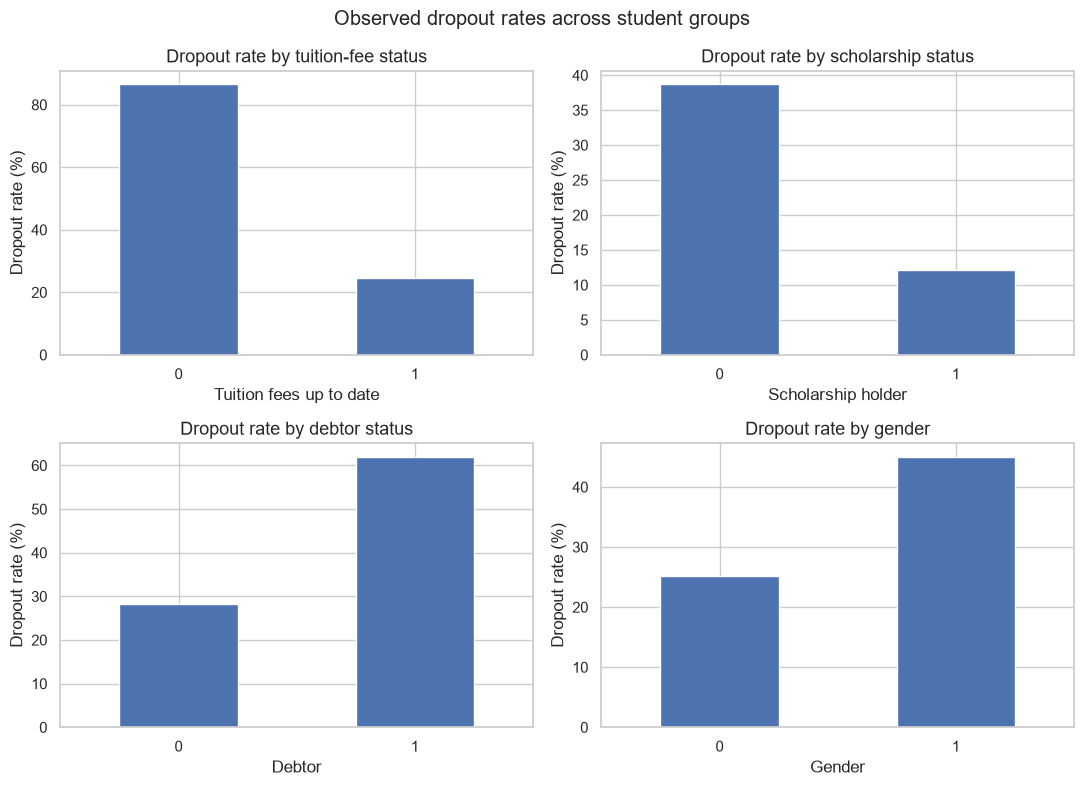

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
panel_columns = [
    ("Tuition fees up to date", "Dropout rate by tuition-fee status"),
    ("Scholarship holder", "Dropout rate by scholarship status"),
    ("Debtor", "Dropout rate by debtor status"),
    ("Gender", "Dropout rate by gender"),
]
for ax, (column, title) in zip(axes.flat, panel_columns):
    rates = data.groupby(column, observed=True)["dropout"].mean().mul(100)
    rates.plot(kind="bar", ax=ax, color="#4c72b0")
    ax.set_title(title)
    ax.set_xlabel(column)
    ax.set_ylabel("Dropout rate (%)")
    ax.tick_params(axis="x", rotation=0)
fig.suptitle("Observed dropout rates across student groups")
save_figure("fig03_group_dropout_rates.png")
plt.show()


### What and why
Use a correlation heatmap for numeric variables and list the ten strongest correlations with dropout. Correlation indicates association, not causation.

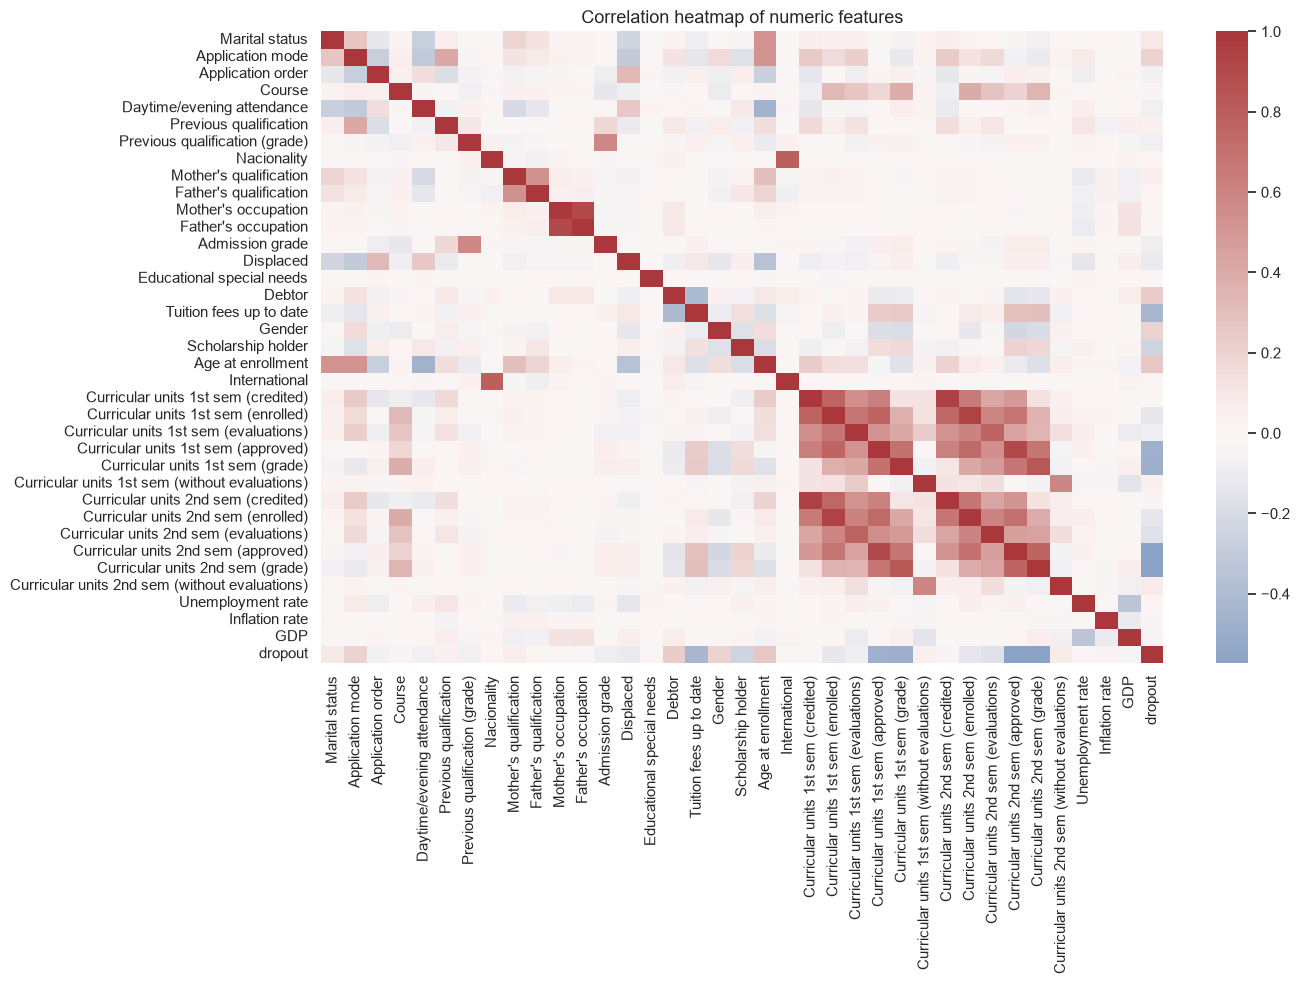

,absolute_correlation
Curricular units 2nd sem (grade),0.571792
Curricular units 2nd sem (approved),0.569500
Curricular units 1st sem (grade),0.480669
Curricular units 1st sem (approved),0.479112
Tuition fees up to date,0.429149
Age at enrollment,0.254215
Scholarship holder,0.245354
Debtor,0.229407
Gender,0.203983
Application mode,0.198458


In [7]:
numeric = data.select_dtypes(include=np.number)
correlation = numeric.corr()
plt.figure(figsize=(14, 10))
sns.heatmap(correlation, cmap="vlag", center=0)
plt.title("Correlation heatmap of numeric features")
save_figure("fig02_correlation_heatmap.png")
plt.show()

top_correlations = correlation["dropout"].drop("dropout").abs().sort_values(ascending=False).head(10)
display(top_correlations.to_frame("absolute_correlation"))


### What and why
The chi-square test checks whether tuition-fee status and dropout are associated. A small p-value suggests the observed group difference is unlikely under independence.

In [8]:
table = pd.crosstab(data["Tuition fees up to date"], data["dropout"])
chi2, p_value, dof, expected = chi2_contingency(table)
print(f"Chi-square={chi2:.2f}, degrees of freedom={dof}, p-value={p_value:.4g}")
print("Interpretation:", "evidence of an association" if p_value < 0.05 else "not enough evidence of an association", "at the 5% level.")


Chi-square=811.93, degrees of freedom=1, p-value=1.374e-178
Interpretation: evidence of an association at the 5% level.


### What and why
The independent t-test compares average second-semester approved units for dropout and non-dropout students. It tests a difference in means, while not claiming causality.

In [9]:
dropout_units = data.loc[data["dropout"] == 1, "Curricular units 2nd sem (approved)"]
other_units = data.loc[data["dropout"] == 0, "Curricular units 2nd sem (approved)"]
t_stat, p_value = ttest_ind(dropout_units, other_units, equal_var=False)
print(f"Dropout mean={dropout_units.mean():.2f}; non-dropout mean={other_units.mean():.2f}")
print(f"Welch t={t_stat:.2f}, p-value={p_value:.4g}")
print("Interpretation:", "the group means differ significantly" if p_value < 0.05 else "no statistically clear mean difference", "at the 5% level.")


Dropout mean=1.94; non-dropout mean=5.62
Welch t=-45.15, p-value=0
Interpretation: the group means differ significantly at the 5% level.


## Conclusion

The dataset is compact, has a binary dropout target, and can be analysed without imputation because the supplied file has no missing values. Group rates, correlations, and tests provide context; they do not replace leakage-safe predictive evaluation.